# Los mismo que en cats_vs_dogs pero más limpio y organizado (centrandonos en ResNet18).

In [1]:
# TODAS las librerias necesarias
import time
import copy
import torch
import matplotlib.pyplot as plt
from torch import nn
from torchvision import models
from datos import crear_loaders
from PIL import Image
import numpy as np
import pandas as pd
from torch.optim.lr_scheduler import CosineAnnealingLR

### Device ---> GPU:

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

## CNN propia (con augmentation):

In [3]:
def bloque(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), # padding=1 con kernel 3×3. Mantiene el tamaño espacial.
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2), # Es el MaxPool2d(2) el que lo reduce a la mitad en cada bloque: (divide la 
                         # imagen en bloques 2x2 y se queda con el pixel de mayor intensidad en cada bloque)
    )

class CNNPerrosGatos(nn.Module):
    def __init__(self, canales=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        bloques, c_in = [], 3
        for c in canales:
            bloques.append(bloque(c_in, c))
            c_in = c
        self.features = nn.Sequential(*bloques)
        self.pool = nn.AdaptiveAvgPool2d(1)            # [B, C, H, W] -> [B, C, 1, 1]
        self.classifier = nn.Sequential(
            nn.Flatten(),                              # -> [B, 256]
            nn.Dropout(dropout),
            nn.Linear(c_in, 1),                        # un solo logit
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x).squeeze(1)           # [B, 1] -> [B]

model = CNNPerrosGatos().to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))   # 389.633

Parámetros: 389633


In [4]:
USO_AMP = True                                   # pon False para comparar velocidades
torch.backends.cudnn.benchmark = True            # elige los algoritmos de convolución más rápidos
                                                 # (útil porque todas las entradas tienen el mismo tamaño)
def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16,
                          enabled=USO_AMP and device == "cuda")

def entrenar_una_epoca(model, loader, loss_fn, optimizer):
    model.train()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with autocast():
            pred = model(x)
            loss = loss_fn(pred.float(), y)      # la pérdida siempre en float32

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        perdida_total += loss.detach() * len(y)  # ponderada: el último lote es más pequeño
        correctas += ((pred.detach() > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def evaluar(model, loader, loss_fn):
    model.eval()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with autocast():
                pred = model(x)
            perdida_total += loss_fn(pred.float(), y) * len(y)
            correctas += ((pred > 0).float() == y).sum()
            n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def entrenar(model, train_loader, val_loader, epocas=15, lr=1e-3, weight_decay=1e-4):
    loss_fn = nn.BCEWithLogitsLoss()
    """ Ya no usamos model.parameters() para entrena el modelo en el optimizador, ya que ahora hay parámetros
    que hemos congelado por lo que no son entrenables !!!!"""
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor = {"val_loss": float("inf"), "epoca": 0, "estado": None}

    for epoca in range(1, epocas + 1):
        t0 = time.time()
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
        vl, va = evaluar(model, val_loader, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)

        if vl < mejor["val_loss"]:
            mejor = {"val_loss": vl, "epoca": epoca, "estado": copy.deepcopy(model.state_dict())} # guardamos los pesos de la época 
                                                                                                  # con menor pérdida de validación.

        print(f"Época {epoca:2d}/{epocas} | {time.time() - t0:4.1f} s | "
              f"train: {tl:.4f} ({ta:.1%}) | val: {vl:.4f} ({va:.1%})")
    return h, mejor

def dibujar_historial(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(ep, h["train_loss"], marker="o", label="Train")
    ax1.plot(ep, h["val_loss"], marker="o", label="Validación")
    ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida")
    ax1.set_title("Pérdida por época"); ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(ep, [a * 100 for a in h["train_acc"]], marker="o", label="Train")
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label="Validación")
    ax2.axhline(50, color="gray", linestyle="--", label="Azar (50 %)")
    ax2.set_xlabel("Época"); ax2.set_ylabel("Precisión (%)")
    ax2.set_title("Precisión por época"); ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout(); plt.show()

Época  1/30 | 154.3 s | train: 0.5978 (67.8%) | val: 0.7268 (61.8%)
Época  2/30 | 10.9 s | train: 0.5363 (73.5%) | val: 0.5107 (75.8%)
Época  3/30 | 10.8 s | train: 0.4804 (77.6%) | val: 0.5185 (73.2%)
Época  4/30 | 10.8 s | train: 0.4255 (80.4%) | val: 0.5101 (75.4%)
Época  5/30 | 10.8 s | train: 0.3942 (82.5%) | val: 0.4119 (79.9%)
Época  6/30 | 10.8 s | train: 0.3541 (84.7%) | val: 0.3242 (86.3%)
Época  7/30 | 10.7 s | train: 0.3377 (85.4%) | val: 0.4200 (80.1%)
Época  8/30 | 10.8 s | train: 0.3140 (86.6%) | val: 0.5863 (74.5%)
Época  9/30 | 10.7 s | train: 0.3022 (87.0%) | val: 0.2807 (88.8%)
Época 10/30 | 10.8 s | train: 0.2870 (87.8%) | val: 0.2930 (87.7%)
Época 11/30 | 10.8 s | train: 0.2733 (88.7%) | val: 0.2438 (90.0%)
Época 12/30 | 11.2 s | train: 0.2637 (88.8%) | val: 0.3119 (88.6%)
Época 13/30 | 10.9 s | train: 0.2493 (89.7%) | val: 0.8574 (71.2%)
Época 14/30 | 11.1 s | train: 0.2377 (90.1%) | val: 0.2456 (90.7%)
Época 15/30 | 10.7 s | train: 0.2341 (90.3%) | val: 0.2983 (8

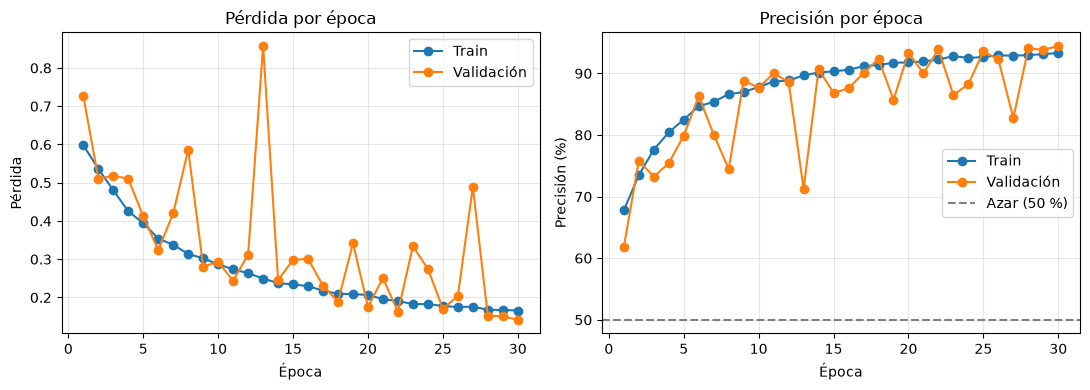

In [5]:
train_loader, val_loader, test_loader, test_files = crear_loaders(num_workers=14, augmentation=True)

torch.manual_seed(0)
model = CNNPerrosGatos().to(device)
historial_aug, mejor_aug = entrenar(model, train_loader, val_loader, epocas=30)
print(f"Mejor época: {mejor_aug['epoca']}")
torch.save(mejor_aug["estado"], "cnn_aug.pt")

dibujar_historial(historial_aug)

## ResNet18:

In [6]:
class ResNetPerrosGatos(nn.Module):
    def __init__(self, congelar=True, dropout=0.2):
        super().__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone.fc = nn.Identity()                 # quitamos la capa de 1000 clases -> sale [B, 512]
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(512, 1))   # capa nueva
        self.congelar_backbone(congelar)

    def congelar_backbone(self, congelar=True):
        self.congelado = congelar
        for p in self.backbone.parameters():
            p.requires_grad = not congelar

    def train(self, mode=True):
        super().train(mode)
        if self.congelado:
            self.backbone.eval()      # mantiene las BatchNorm del backbone en modo evaluación
        return self

    def forward(self, x):
        return self.head(self.backbone(x)).squeeze(1)    # [B, 512] -> [B, 1] -> [B]

model = ResNetPerrosGatos(congelar=True).to(device)

total = sum(p.numel() for p in model.parameters())
entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales: {total:,} | entrenables: {entrenables:,}")
# 11,177,025 totales | 513 entrenables

Parámetros totales: 11,177,025 | entrenables: 513


### Comprobaciones para ver si todo va correcto en la ResNet:

In [7]:
model.train()
print("backbone en eval:", not model.backbone.training)       # True
print("bn1.training:", model.backbone.bn1.training)           # False
print("head.training:", model.head.training)                  # True

# Una pasada para comprobar formas
x = torch.randn(4, 3, 128, 128, device=device)
print(model(x).shape)                                         # torch.Size([4])

backbone en eval: True
bn1.training: False
head.training: True
torch.Size([4])


In [8]:
antes = model.backbone.layer4[1].bn2.running_mean.clone()
entrenar_una_epoca(model, train_loader, nn.BCEWithLogitsLoss(),
                   torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3))
despues = model.backbone.layer4[1].bn2.running_mean
print("¿Estadísticas BN sin cambios?", torch.equal(antes, despues))   # True

¿Estadísticas BN sin cambios? True


### Entrenar ResNet (última capa):

Época  1/5 | 11.6 s | train: 0.1442 (94.0%) | val: 0.0870 (96.5%)
Época  2/5 | 10.8 s | train: 0.1000 (96.0%) | val: 0.0849 (96.6%)
Época  3/5 | 10.6 s | train: 0.0963 (96.2%) | val: 0.0823 (96.6%)
Época  4/5 | 10.8 s | train: 0.0945 (96.2%) | val: 0.0827 (96.7%)
Época  5/5 | 10.8 s | train: 0.0961 (96.1%) | val: 0.0793 (96.9%)


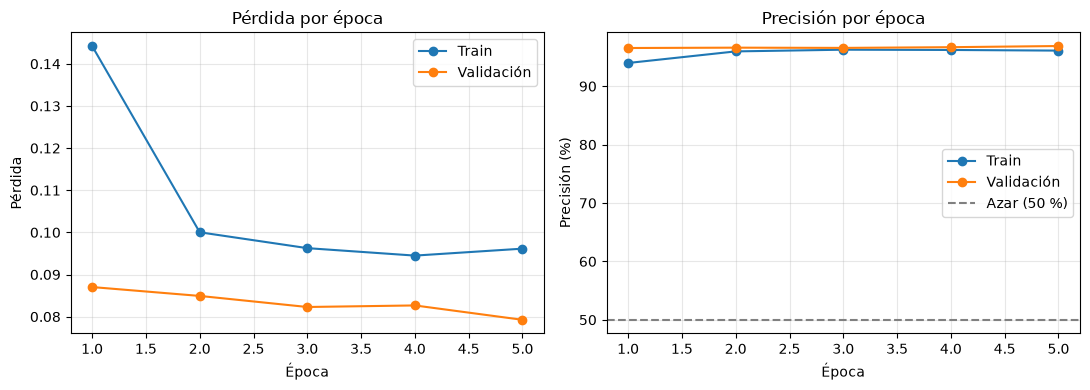

In [9]:
historial_aug_prev = historial_aug          # guarda el resultado del paso 5 para comparar

torch.manual_seed(0)
model = ResNetPerrosGatos(congelar=True).to(device)
historial_tl, mejor_tl = entrenar(model, train_loader, val_loader, epocas=5, lr=1e-3)
torch.save(mejor_tl["estado"], "resnet18_cabeza.pt")

dibujar_historial(historial_tl)

### Comprobaciones:

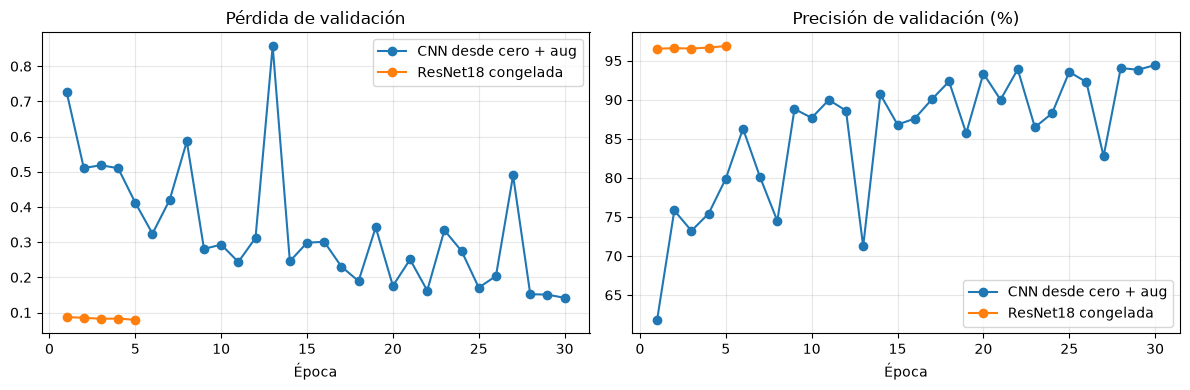

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for h, nombre in [(historial_aug_prev, "CNN desde cero + aug"), (historial_tl, "ResNet18 congelada")]:
    ep = range(1, len(h["val_loss"]) + 1)
    ax1.plot(ep, h["val_loss"], marker="o", label=nombre)
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label=nombre)
ax1.set_title("Pérdida de validación"); ax2.set_title("Precisión de validación (%)")
for ax in (ax1, ax2):
    ax.set_xlabel("Época"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Paso 7: Fine-tuning, análisis de errores y predicciones.

En el paso 6 el backbone estaba congelado y solo entrenamos la capa nueva. Ahora descongelamos las últimas etapas (layer3 y layer4) y las ajustamos a perros y gatos, con un learning rate pequeño para no destruir lo que ya saben.

**Por qué solo las últimas etapas**. Las primeras capas detectan bordes y texturas, que sirven para cualquier imagen. Las últimas son las más específicas, y son las que más se benefician de adaptarse. Además, entrenar menos capas es más rápido y arriesga menos sobreajuste.

**Por qué un learning rate pequeño**. Los pesos del backbone ya son buenos. Con lr=1e-3 los estropearías en los primeros lotes, porque la capa nueva todavía comete errores grandes y esos gradientes arrastran al backbone. Usamos learning rates distintos por grupo: 1e-4 para el backbone y 1e-3 para la capa nueva.

### Paso 1: una versión mejorada de la clase

Sustituye a la del paso 6. Los pesos guardados en resnet18_cabeza.pt siguen siendo compatibles. La diferencia es que ahora se puede elegir qué bloques entrenan, y los demás quedan siempre en modo evaluación (también sus BatchNorm, como vimos en el paso 6):

In [11]:
class ResNetPerrosGatos(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(512, 1))
        self.fijar_entrenables(())                       # por defecto: backbone congelado

    def fijar_entrenables(self, bloques):
        """bloques: nombres de los bloques del backbone que se entrenan, p. ej. ('layer3', 'layer4')."""
        self.entrenables = tuple(bloques)
        for nombre, m in self.backbone.named_children():
            for p in m.parameters():
                p.requires_grad = nombre in self.entrenables

    def train(self, mode=True):
        super().train(mode)
        if mode:
            for nombre, m in self.backbone.named_children():
                if nombre not in self.entrenables:
                    m.eval()                              # congelado también en BatchNorm
        return self

    def forward(self, x):
        return self.head(self.backbone(x)).squeeze(1)

model = ResNetPerrosGatos().to(device)
model.load_state_dict(torch.load("resnet18_cabeza.pt"))   # partimos de la cabeza ya entrenada. Es importante. Si descongelaras 
                                                          # con una capa final aleatoria, los gradientes iniciales serían enormes 
                                                          # y corromperían el backbone.
model.fijar_entrenables(("layer3", "layer4"))

total = sum(p.numel() for p in model.parameters())
entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Totales: {total:,} | entrenables: {entrenables:,}")     # ~11.2 M | ~10.5 M

Totales: 11,177,025 | entrenables: 10,493,953


### Paso 2: entrenar con learning rates por grupo y scheduler:

Época 1/8 | 16.4 s | train: 0.1112 (95.6%) | val: 0.0691 (97.2%)
Época 2/8 | 11.8 s | train: 0.0638 (97.6%) | val: 0.0571 (97.7%)
Época 3/8 | 11.8 s | train: 0.0440 (98.3%) | val: 0.0573 (97.7%)
Época 4/8 | 11.4 s | train: 0.0343 (98.8%) | val: 0.0596 (97.8%)
Época 5/8 | 12.0 s | train: 0.0262 (99.1%) | val: 0.0517 (98.0%)
Época 6/8 | 11.9 s | train: 0.0175 (99.4%) | val: 0.0545 (98.3%)
Época 7/8 | 11.4 s | train: 0.0146 (99.5%) | val: 0.0519 (98.2%)
Época 8/8 | 11.3 s | train: 0.0138 (99.5%) | val: 0.0511 (98.2%)
Mejor época: 8


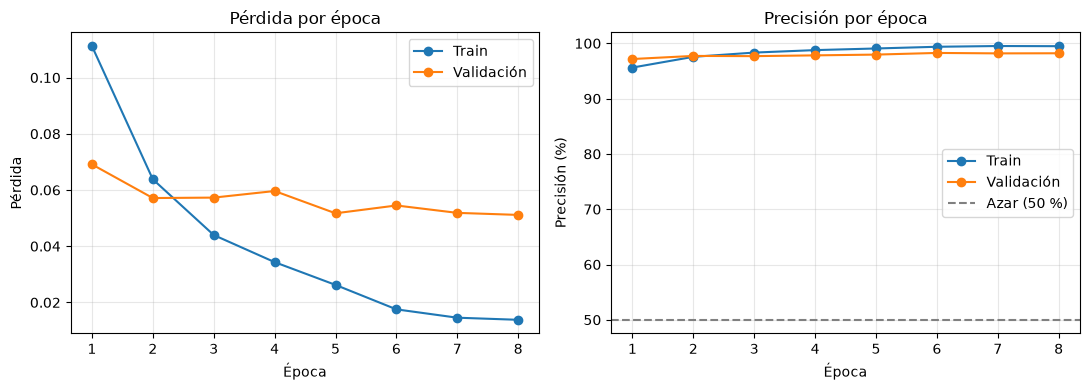

In [12]:
def entrenar_ft(model, train_loader, val_loader, epocas=8,
                lr_backbone=1e-4, lr_head=1e-3, weight_decay=1e-4):
    loss_fn = nn.BCEWithLogitsLoss()
    params_backbone = [p for n in model.entrenables for p in getattr(model.backbone, n).parameters()]
    optimizer = torch.optim.AdamW(
        [{"params": params_backbone, "lr": lr_backbone},
         {"params": model.head.parameters(), "lr": lr_head}],
        weight_decay=weight_decay)
    scheduler = CosineAnnealingLR(optimizer, T_max=epocas)      # el lr baja suavemente hasta ~0

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor = {"val_loss": float("inf"), "epoca": 0, "estado": None}
    for epoca in range(1, epocas + 1):
        t0 = time.time()
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
        vl, va = evaluar(model, val_loader, loss_fn)
        scheduler.step()
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)
        if vl < mejor["val_loss"]:
            mejor = {"val_loss": vl, "epoca": epoca, "estado": copy.deepcopy(model.state_dict())}
        print(f"Época {epoca}/{epocas} | {time.time() - t0:4.1f} s | "
              f"train: {tl:.4f} ({ta:.1%}) | val: {vl:.4f} ({va:.1%})")
    return h, mejor

torch.manual_seed(0)
historial_ft, mejor_ft = entrenar_ft(model, train_loader, val_loader, epocas=8)
print("Mejor época:", mejor_ft["epoca"])
torch.save(mejor_ft["estado"], "resnet18_finetuned.pt")
dibujar_historial(historial_ft)

#### ¿Que cambia?:

* El optimizador recibe una lista de diccionarios, cada uno con sus parámetros y su lr. Es el mecanismo estándar para tener learning rates discriminativos: más pequeño donde ya hay conocimiento, más grande donde hay que aprender.

* CosineAnnealingLR. Reduce el learning rate siguiendo una curva de coseno, desde su valor inicial hasta casi 0 al final del entrenamiento. Al principio da pasos grandes y al final pasos muy finos, que es justo lo que se quiere al ajustar un modelo ya bueno. Se llama a scheduler.step() una vez por época, después de entrenar.

* fijar_entrenables(("layer3", "layer4")). Los bloques conv1, bn1, layer1 y layer2 siguen congelados, y también en eval(). Así no hay que guardar activaciones para el backward de esas capas, lo que ahorra tiempo y memoria.

### Paso 3: análisis de errores

Es la parte que más enseña: ver qué fotos falla el modelo. Primero, una función para obtener las probabilidades con TTA (promediando la imagen con su volteo, como en el paso 5):

In [13]:
@torch.no_grad()
def predecir_probs(model, loader, tta=True):
    model.eval()
    salida = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch     # val trae (x, y); test solo x
        x = x.to(device, non_blocking=True)
        with autocast():
            logit = model(x).float()
            if tta:
                logit = (logit + model(torch.flip(x, dims=[3])).float()) / 2
        salida.append(torch.sigmoid(logit).cpu())
    return torch.cat(salida).numpy()

model.load_state_dict(mejor_ft["estado"])
y_val = val_loader.dataset.labels.numpy()
p_val = predecir_probs(model, val_loader)
pred = (p_val > 0.5).astype(int)

print(f"Precisión de validación (con TTA): {(pred == y_val).mean():.2%}")
tn = ((pred == 0) & (y_val == 0)).sum(); fp = ((pred == 1) & (y_val == 0)).sum()
fn = ((pred == 0) & (y_val == 1)).sum(); tp = ((pred == 1) & (y_val == 1)).sum()
print(f"Gatos bien: {tn} | gatos clasificados como perro: {fp}")
print(f"Perros bien: {tp} | perros clasificados como gato: {fn}")

Precisión de validación (con TTA): 98.34%
Gatos bien: 2462 | gatos clasificados como perro: 38
Perros bien: 2455 | perros clasificados como gato: 45


Y las peores equivocaciones, ordenadas por lo seguro que estaba el modelo de su error::

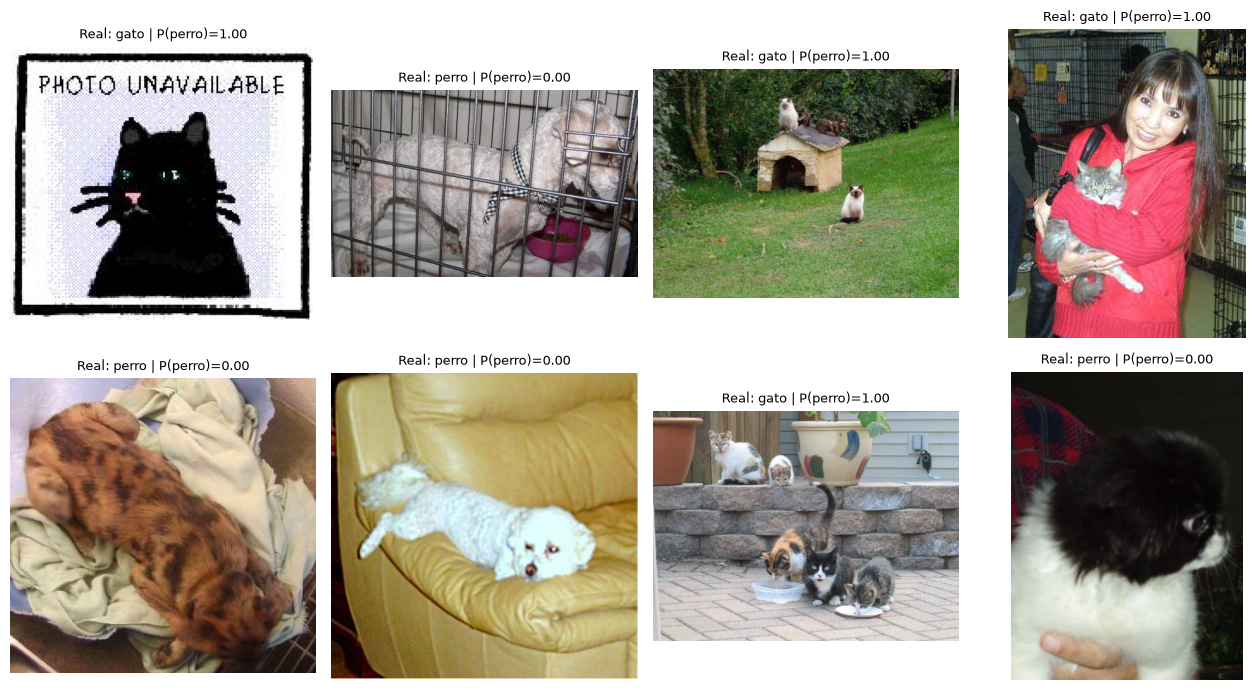

In [14]:
rutas_val = val_loader.dataset.paths
error_confianza = np.abs(p_val - y_val)                    # 1.0 = muy seguro y muy equivocado
peores = np.argsort(-error_confianza * (pred != y_val))[:8]

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, i in zip(axes.flat, peores):
    ax.imshow(Image.open(rutas_val[i]).convert("RGB"))
    real = "perro" if y_val[i] == 1 else "gato"
    ax.set_title(f"Real: {real} | P(perro)={p_val[i]:.2f}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

### Paso 4: generar el archivo de predicciones

In [15]:
p_test = predecir_probs(model, test_loader)                 # test_loader: sin shuffle, orden numérico
ids = [int(p.stem) for p in test_files]                     # 1, 2, ..., 12500

assert len(p_test) == len(ids) == 12500

sub = pd.DataFrame({"id": ids, "label": (p_test > 0.5).astype(int)})        # 1 = perro, 0 = gato
sub.to_csv("submission.csv", index=False)

sub_prob = pd.DataFrame({"id": ids, "label": np.clip(p_test, 0.02, 0.98)})  # probabilidades
sub_prob.to_csv("submission_prob.csv", index=False)

print(sub.shape, sub["id"].is_monotonic_increasing)         # (12500, 2) True
print(sub.head())
print("Proporción de perros predicha:", sub["label"].mean().round(3))      # ~0.5
print("Proporción en validación real:", y_val.mean().round(3))

(12500, 2) True
   id  label
0   1      1
1   2      1
2   3      1
3   4      1
4   5      0
Proporción de perros predicha: 0.497
Proporción en validación real: 0.5


## Probarlo con tus propias fotos

In [16]:
from datos import transform_eval

def predecir_foto(ruta):
    img = Image.open(ruta).convert("RGB")
    x = transform_eval(img).unsqueeze(0).to(device)         # [1, 3, 128, 128]
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(x)).item()
    return ("perro" if p > 0.5 else "gato"), p

print(predecir_foto(r"dogs-vs-cats\timmy.jpeg"))       # ('gato', 0.03)

('gato', 0.0648726224899292)
